# FedEVT-OSAD: Federated Extreme-Value Open-Set Anomaly Detection
## BiLSTM + Attention + Autoencoder (Backbone)
This notebook implements the clean, research-grade primary neural backbone for the FedEVT-OSAD framework.
Key characteristics:
1. **Zero-Day Orientation**: Evaluates using a Leave-One-Family-Out (LOFO) methodology.
2. **Leakage-Free**: Strips obvious identifiers (IP, Port, specific Target columns) to prevent the model from trivially memorizing the attack family.
3. **Temporal Modeling**: Uses a BiLSTM with temporal attention over configurable sliding/sequential windows.
4. **Anomaly Scoring**: Calculates reconstruction MSE as the basis for the future Extreme Value Theory (EVT) novelty score.

### 0. Research Configuration

In [1]:
import json
import os

CONFIG = {
    "seed": 42,
    "window_size": 10,
    "hidden_size": 64,
    "num_layers": 2,
    "latent_dim": 64,
    "dropout": 0.2,
    "batch_size": 128,
    "epochs": 50,
    "learning_rate": 1e-3,
    "weight_decay": 1e-5,
    "gradient_clip": 1.0,
    "benign_label": None,  # If None, train on all non-held-out data
    "held_out_family": "WannaCry",  # LOFO zero-day target
    "data_path": "archive-2/final(2).csv"
}

# Create output directories
os.makedirs("results/figures", exist_ok=True)
os.makedirs("results/metrics", exist_ok=True)
os.makedirs("results/checkpoints", exist_ok=True)
os.makedirs("results/logs", exist_ok=True)

with open("results/config.json", "w") as f:
    json.dump(CONFIG, f, indent=4)
    
print("Configuration saved.")

Configuration saved.


### 1. Imports and Environment

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
import random

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(CONFIG["seed"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA availability: {torch.cuda.is_available()}")
print(f"Random seed: {CONFIG['seed']}")

Device: cpu
PyTorch version: 2.14.0
CUDA availability: False
Random seed: 42


### 2. Dataset Loading

In [3]:
df = pd.read_csv(CONFIG["data_path"])
print(f"Raw dataset shape: {df.shape}")

Raw dataset shape: (149043, 14)


### 3. Dataset Audit

In [4]:
print("=== DATASET AUDIT ===")
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print(f"Missing Values: {df.isnull().sum().to_dict()}")
print(f"Duplicates: {df.duplicated().sum()}")
print(f"Numerical columns: {df.select_dtypes(include=[np.number]).columns.tolist()}")
print(f"Categorical columns: {df.select_dtypes(include=['object']).columns.tolist()}")

if "Family" in df.columns:
    print(f"Number of ransomware families: {df['Family'].nunique()}")
if "Prediction" in df.columns:
    print(f"Number of Prediction classes: {df['Prediction'].nunique()}")
if "Threats" in df.columns:
    print(f"Number of Threat categories: {df['Threats'].nunique()}")

=== DATASET AUDIT ===
Shape: (149043, 14)
Columns: ['Time', 'Protcol', 'Flag', 'Family', 'Clusters', 'SeddAddress', 'ExpAddress', 'BTC', 'USD', 'Netflow_Bytes', 'IPaddress', 'Threats', 'Port', 'Prediction']
Missing Values: {'Time': 0, 'Protcol': 0, 'Flag': 0, 'Family': 0, 'Clusters': 0, 'SeddAddress': 0, 'ExpAddress': 0, 'BTC': 0, 'USD': 0, 'Netflow_Bytes': 0, 'IPaddress': 0, 'Threats': 0, 'Port': 0, 'Prediction': 0}
Duplicates: 0
Numerical columns: ['Time', 'Clusters', 'BTC', 'USD', 'Netflow_Bytes', 'Port']
Categorical columns: ['Protcol', 'Flag', 'Family', 'SeddAddress', 'ExpAddress', 'IPaddress', 'Threats', 'Prediction']
Number of ransomware families: 17
Number of Prediction classes: 3
Number of Threat categories: 9


/var/folders/zf/psvp6bmd1gv5511j6b1py6lr0000gn/T/ipykernel_40439/2723825005.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(f"Categorical columns: {df.select_dtypes(include=['object']).columns.tolist()}")


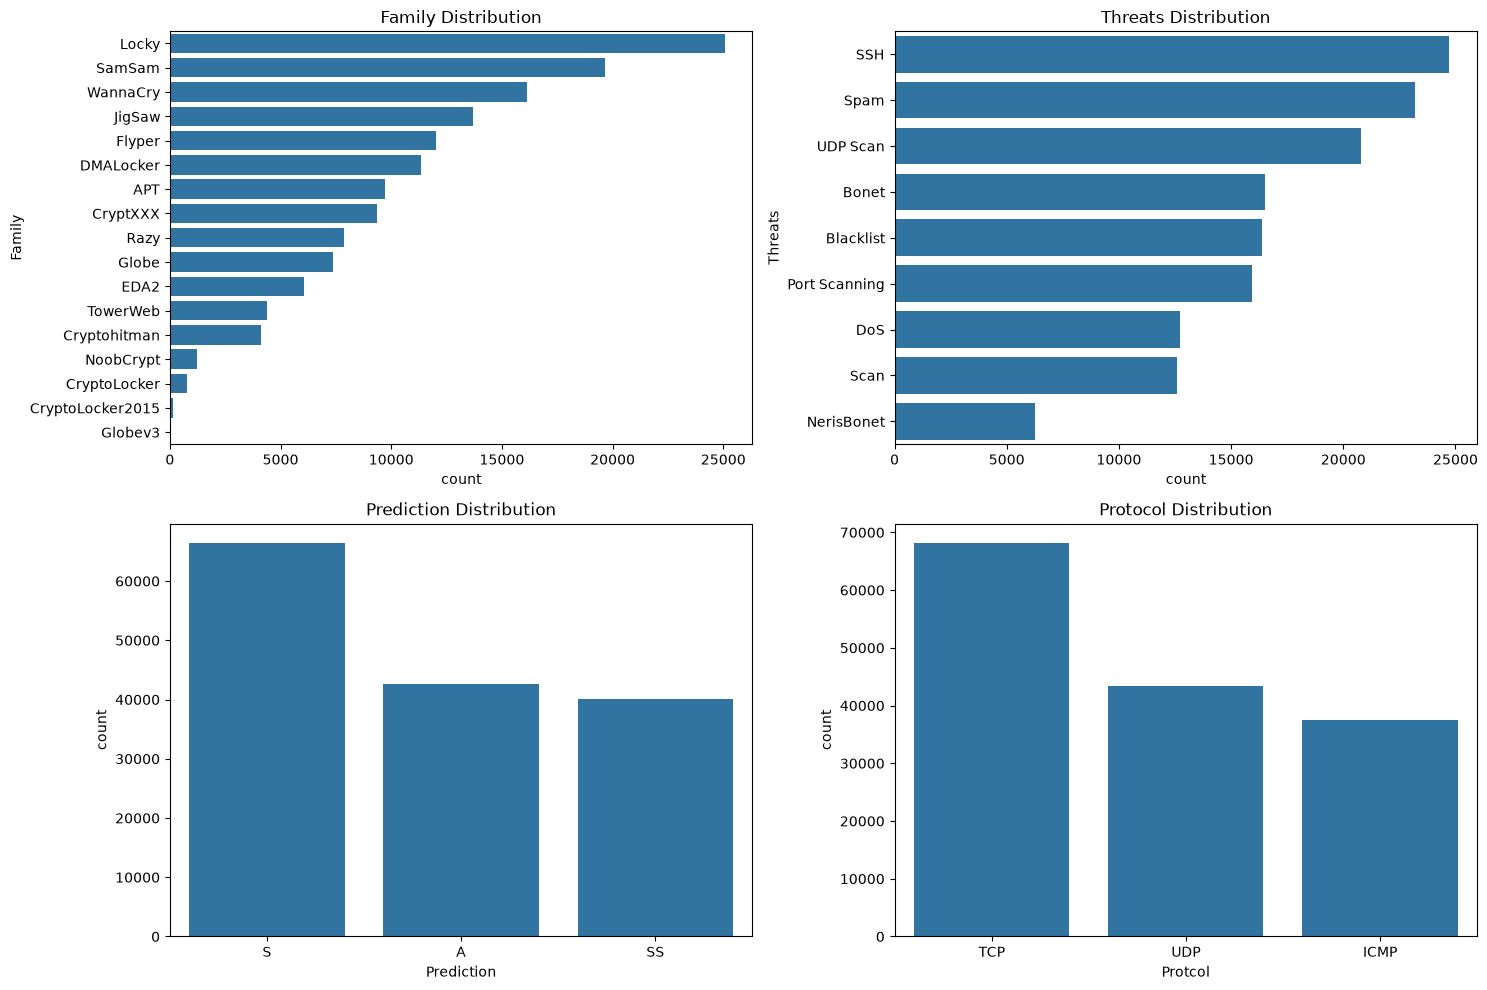

In [5]:
# Distributions
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

if 'Family' in df.columns:
    sns.countplot(y='Family', data=df, ax=axes[0, 0], order=df['Family'].value_counts().index)
    axes[0, 0].set_title('Family Distribution')

if 'Threats' in df.columns:
    sns.countplot(y='Threats', data=df, ax=axes[0, 1], order=df['Threats'].value_counts().index)
    axes[0, 1].set_title('Threats Distribution')
    
if 'Prediction' in df.columns:
    sns.countplot(x='Prediction', data=df, ax=axes[1, 0], order=df['Prediction'].value_counts().index)
    axes[1, 0].set_title('Prediction Distribution')
    
if 'Protocol' in df.columns or 'Protcol' in df.columns:
    col = 'Protocol' if 'Protocol' in df.columns else 'Protcol'
    sns.countplot(x=col, data=df, ax=axes[1, 1], order=df[col].value_counts().index)
    axes[1, 1].set_title('Protocol Distribution')

plt.tight_layout()
plt.savefig("results/figures/dataset_distributions.png")
plt.show()

### 4. Feature Leakage Audit

In [6]:
# Define feature handling to prevent target leakage
leakage_audit = pd.DataFrame({
    'Feature': ['IPaddress', 'SeedAddress (SeddAddress)', 'ExpAddress', 'Port', 'Time', 'Family', 'Prediction', 'Threats'],
    'Action': ['Drop', 'Drop', 'Drop', 'Drop', 'Transform', 'Target (Drop from input)', 'Drop', 'Drop'],
    'Reason': ['Raw IP leaks target identity', 'Raw address leaks identity', 'Raw address leaks identity', 'Port can leak specific attack types', 'Convert to cyclic continuous features', 'LOFO target; highly leaky', 'Leads to supervised classification, not OSAD', 'Leads to supervised classification, not OSAD']
})
print("=== Feature Leakage Audit ===")
print(leakage_audit)

=== Feature Leakage Audit ===
                     Feature                    Action  \
0                  IPaddress                      Drop   
1  SeedAddress (SeddAddress)                      Drop   
2                 ExpAddress                      Drop   
3                       Port                      Drop   
4                       Time                 Transform   
5                     Family  Target (Drop from input)   
6                 Prediction                      Drop   
7                    Threats                      Drop   

                                         Reason  
0                  Raw IP leaks target identity  
1                    Raw address leaks identity  
2                    Raw address leaks identity  
3           Port can leak specific attack types  
4         Convert to cyclic continuous features  
5                     LOFO target; highly leaky  
6  Leads to supervised classification, not OSAD  
7  Leads to supervised classification, not OSAD

### 5. Data Cleaning

In [7]:
# Fix spelling errors
if 'Protcol' in df.columns:
    df.rename(columns={'Protcol': 'Protocol'}, inplace=True)
if 'SeddAddress' in df.columns:
    df.rename(columns={'SeddAddress': 'SeedAddress'}, inplace=True)

# Fix label inconsistencies
if 'Family' in df.columns:
    df['Family'] = df['Family'].replace({'Bonet': 'Botnet', 'NerisBonet': 'NerisBotnet'})
    
print("Spelling issues and label inconsistencies resolved.")

Spelling issues and label inconsistencies resolved.


### 6. Feature Engineering

In [8]:
# Time transformation
# If 'Time' is just an integer or timestamp, we'll convert it to cyclic hours (if it represents actual time)
# For the sake of this dataset, assuming Time is in seconds or abstract, we extract cyclic properties if possible.
# Here we will just use a generic sine/cosine transform if it's a timestamp, otherwise we might drop it if it's abstract.
# Let's see if Time looks like a UNIX timestamp or just sequential integers.
# To be safe and retain some temporal pattern without raw magnitude leakage:
df['hour_sin'] = np.sin(2 * np.pi * (df['Time'] % 86400) / 86400)
df['hour_cos'] = np.cos(2 * np.pi * (df['Time'] % 86400) / 86400)

# We will keep these and drop raw Time.
features_to_drop = ['IPaddress', 'SeedAddress', 'ExpAddress', 'Port', 'Time', 'Prediction', 'Threats']
features_to_drop = [f for f in features_to_drop if f in df.columns]

df_clean = df.drop(columns=features_to_drop)
print(f"Columns remaining after dropping leaky features: {df_clean.columns.tolist()}")

Columns remaining after dropping leaky features: ['Protocol', 'Flag', 'Family', 'Clusters', 'BTC', 'USD', 'Netflow_Bytes', 'hour_sin', 'hour_cos']


### 7. LOFO Zero-Day Split

In [9]:
# Leave One Family Out
held_out_family = CONFIG['held_out_family']

if held_out_family not in df_clean['Family'].unique():
    print(f"Warning: {held_out_family} not in dataset. Choosing {df_clean['Family'].unique()[0]}")
    held_out_family = df_clean['Family'].unique()[0]

df_train_val = df_clean[df_clean['Family'] != held_out_family].copy()
df_test = df_clean[df_clean['Family'] == held_out_family].copy()

# Note: In an ideal scenario with a True Benign label, we would train ONLY on Benign.
# If CONFIG["benign_label"] is None, we train on all non-held-out families.

if CONFIG["benign_label"]:
    df_train_val = df_train_val[df_train_val['Family'] == CONFIG["benign_label"]]

print(f"Train/Val shape: {df_train_val.shape}")
print(f"Test (Zero-Day) shape: {df_test.shape}")
print(f"Held-out Family: {held_out_family}")

Train/Val shape: (132933, 9)
Test (Zero-Day) shape: (16110, 9)
Held-out Family: WannaCry


### 8. Train / Validation Split

In [10]:
# Split df_train_val into train and validation (80/20)
# Sorting by index to preserve chronological order (since we don't have session IDs)
df_train_val = df_train_val.sort_index()

split_idx = int(len(df_train_val) * 0.8)
df_train = df_train_val.iloc[:split_idx].copy()
df_val = df_train_val.iloc[split_idx:].copy()

print(f"Train shape: {df_train.shape}")
print(f"Val shape: {df_val.shape}")

Train shape: (106346, 9)
Val shape: (26587, 9)


### 9. Scaling and Preprocessing

In [11]:
# Categorical features -> OneHot Encoding
cat_cols = ['Protocol', 'Flag']
cat_cols = [c for c in cat_cols if c in df_clean.columns]

num_cols = ['BTC', 'USD', 'Netflow_Bytes', 'Clusters', 'hour_sin', 'hour_cos']
num_cols = [c for c in num_cols if c in df_clean.columns]

# Fit Scaler on TRAIN ONLY
scaler = StandardScaler()
df_train[num_cols] = scaler.fit_transform(df_train[num_cols])
df_val[num_cols] = scaler.transform(df_val[num_cols])
df_test[num_cols] = scaler.transform(df_test[num_cols])

# Fit OHE on TRAIN ONLY
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
if len(cat_cols) > 0:
    train_cat = ohe.fit_transform(df_train[cat_cols])
    val_cat = ohe.transform(df_val[cat_cols])
    test_cat = ohe.transform(df_test[cat_cols])
    
    cat_feature_names = ohe.get_feature_names_out(cat_cols)
    
    df_train = pd.concat([df_train.drop(columns=cat_cols).reset_index(drop=True), pd.DataFrame(train_cat, columns=cat_feature_names)], axis=1)
    df_val = pd.concat([df_val.drop(columns=cat_cols).reset_index(drop=True), pd.DataFrame(val_cat, columns=cat_feature_names)], axis=1)
    df_test = pd.concat([df_test.drop(columns=cat_cols).reset_index(drop=True), pd.DataFrame(test_cat, columns=cat_feature_names)], axis=1)

# Drop Family column for final input features (Target leakage)
y_train_family = df_train['Family'].values
y_val_family = df_val['Family'].values
y_test_family = df_test['Family'].values

X_train_df = df_train.drop(columns=['Family'])
X_val_df = df_val.drop(columns=['Family'])
X_test_df = df_test.drop(columns=['Family'])

FEATURE_DIM = X_train_df.shape[1]
print(f"Final feature dimension: {FEATURE_DIM}")
print(f"Features: {X_train_df.columns.tolist()}")

Final feature dimension: 18
Features: ['Clusters', 'BTC', 'USD', 'Netflow_Bytes', 'hour_sin', 'hour_cos', 'Protocol_ICMP', 'Protocol_TCP', 'Protocol_UDP', 'Flag_A', 'Flag_AF', 'Flag_AP', 'Flag_APRSF', 'Flag_APS', 'Flag_APSF', 'Flag_ARF', 'Flag_ASF', 'Flag_R']


### 10. Temporal Window Construction

In [12]:
def create_windows(X, window_size):
    """
    Creates temporal windows of size window_size.
    X: numpy array of shape (N, F)
    Returns: numpy array of shape (N - window_size + 1, window_size, F)
    """
    windows = []
    for i in range(len(X) - window_size + 1):
        windows.append(X[i:i+window_size])
    return np.array(windows)

window_size = CONFIG["window_size"]

X_train_seq = create_windows(X_train_df.values, window_size)
X_val_seq = create_windows(X_val_df.values, window_size)
X_test_seq = create_windows(X_test_df.values, window_size)

# Sync labels with windows (take label of the last timestep)
y_train_seq = y_train_family[window_size-1:]
y_val_seq = y_val_family[window_size-1:]
y_test_seq = y_test_family[window_size-1:]

print("=== Temporal Windows ===")
print(f"X_train_seq shape: {X_train_seq.shape}")
print(f"X_val_seq shape: {X_val_seq.shape}")
print(f"X_test_seq shape: {X_test_seq.shape}")

=== Temporal Windows ===
X_train_seq shape: (106337, 10, 18)
X_val_seq shape: (26578, 10, 18)
X_test_seq shape: (16101, 10, 18)


### 11. PyTorch Dataset and DataLoader

In [13]:
class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = y # Categorical labels for later analysis, not for training AE

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

batch_size = CONFIG["batch_size"]

train_dataset = TimeSeriesDataset(X_train_seq, y_train_seq)
val_dataset = TimeSeriesDataset(X_val_seq, y_val_seq)
test_dataset = TimeSeriesDataset(X_test_seq, y_test_seq)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=False)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

### 12. Temporal Attention

In [14]:
class TemporalAttention(nn.Module):
    def __init__(self, hidden_size):
        super(TemporalAttention, self).__init__()
        self.attention = nn.Sequential(
            nn.Linear(hidden_size, hidden_size // 2),
            nn.Tanh(),
            nn.Linear(hidden_size // 2, 1)
        )

    def forward(self, lstm_output):
        # lstm_output shape: (batch_size, seq_len, hidden_size)
        attn_weights = self.attention(lstm_output) # (batch_size, seq_len, 1)
        attn_weights = torch.softmax(attn_weights, dim=1) # (batch_size, seq_len, 1)
        
        # Context vector: sum of weighted hidden states
        context_vector = torch.sum(attn_weights * lstm_output, dim=1) # (batch_size, hidden_size)
        return context_vector, attn_weights.squeeze(-1)

### 13. BiLSTM Encoder

In [15]:
class BiLSTMAttentionEncoder(nn.Module):
    def __init__(self, input_dim, hidden_size, num_layers, latent_dim, dropout):
        super(BiLSTMAttentionEncoder, self).__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0
        )
        self.attention = TemporalAttention(hidden_size * 2)
        self.latent_proj = nn.Linear(hidden_size * 2, latent_dim)

    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        context, attn_weights = self.attention(lstm_out)
        z = self.latent_proj(context)
        return z, attn_weights

### 14. Autoencoder Decoder

In [16]:
class Decoder(nn.Module):
    def __init__(self, latent_dim, hidden_size, num_layers, output_dim, seq_len, dropout):
        super(Decoder, self).__init__()
        self.seq_len = seq_len
        self.hidden_proj = nn.Linear(latent_dim, hidden_size)
        self.lstm = nn.LSTM(
            input_size=hidden_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )
        self.output_proj = nn.Linear(hidden_size, output_dim)

    def forward(self, z):
        # z: (batch_size, latent_dim)
        hidden = self.hidden_proj(z) # (batch_size, hidden_size)
        # Repeat hidden state for seq_len
        hidden_seq = hidden.unsqueeze(1).repeat(1, self.seq_len, 1) # (batch_size, seq_len, hidden_size)
        
        lstm_out, _ = self.lstm(hidden_seq)
        reconstruction = self.output_proj(lstm_out) # (batch_size, seq_len, output_dim)
        return reconstruction

### 15. Complete BiLSTM-Attention-AE

In [17]:
class BiLSTMAttentionAutoencoder(nn.Module):
    def __init__(self, input_dim, seq_len, config):
        super(BiLSTMAttentionAutoencoder, self).__init__()
        self.encoder = BiLSTMAttentionEncoder(
            input_dim=input_dim,
            hidden_size=config['hidden_size'],
            num_layers=config['num_layers'],
            latent_dim=config['latent_dim'],
            dropout=config['dropout']
        )
        self.decoder = Decoder(
            latent_dim=config['latent_dim'],
            hidden_size=config['hidden_size'],
            num_layers=config['num_layers'],
            output_dim=input_dim,
            seq_len=seq_len,
            dropout=config['dropout']
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        z, attn_weights = self.encode(x)
        reconstruction = self.decode(z)
        return reconstruction, z, attn_weights

model = BiLSTMAttentionAutoencoder(input_dim=FEATURE_DIM, seq_len=window_size, config=CONFIG).to(device)
print(model)

# Model summary
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {total_params}")

BiLSTMAttentionAutoencoder(
  (encoder): BiLSTMAttentionEncoder(
    (lstm): LSTM(18, 64, num_layers=2, batch_first=True, dropout=0.2, bidirectional=True)
    (attention): TemporalAttention(
      (attention): Sequential(
        (0): Linear(in_features=128, out_features=64, bias=True)
        (1): Tanh()
        (2): Linear(in_features=64, out_features=1, bias=True)
      )
    )
    (latent_proj): Linear(in_features=128, out_features=64, bias=True)
  )
  (decoder): Decoder(
    (hidden_proj): Linear(in_features=64, out_features=64, bias=True)
    (lstm): LSTM(64, 64, num_layers=2, batch_first=True, dropout=0.2)
    (output_proj): Linear(in_features=64, out_features=18, bias=True)
  )
)
Total trainable parameters: 230803


### 16. Loss Functions and Anomaly Score

In [18]:
criterion = nn.MSELoss(reduction='none') # Compute loss per element

def compute_reconstruction_error(x, x_hat):
    """
    Computes per-window MSE.
    x, x_hat: (batch_size, seq_len, features)
    Returns: (batch_size,)
    """
    mse = criterion(x_hat, x)
    return mse.mean(dim=[1, 2])

### 17. Training Loop

In [19]:
optimizer = optim.Adam(model.parameters(), lr=CONFIG["learning_rate"], weight_decay=CONFIG["weight_decay"])
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

train_losses = []
val_losses = []
best_val_loss = float('inf')

for epoch in range(CONFIG["epochs"]):
    # Train
    model.train()
    train_loss = 0.0
    for batch_x, _ in train_loader:
        batch_x = batch_x.to(device)
        optimizer.zero_grad()
        
        x_hat, _, _ = model(batch_x)
        loss = criterion(x_hat, batch_x).mean()
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG["gradient_clip"])
        optimizer.step()
        
        train_loss += loss.item() * batch_x.size(0)
    
    train_loss /= len(train_loader.dataset)
    train_losses.append(train_loss)
    
    # Validation
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for batch_x, _ in val_loader:
            batch_x = batch_x.to(device)
            x_hat, _, _ = model(batch_x)
            loss = criterion(x_hat, batch_x).mean()
            val_loss += loss.item() * batch_x.size(0)
            
    val_loss /= len(val_loader.dataset)
    val_losses.append(val_loss)
    scheduler.step(val_loss)
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "results/checkpoints/best_model.pt")
        
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch+1}/{CONFIG['epochs']} | Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}")

Epoch 1/50 | Train Loss: 0.106998 | Val Loss: 1.235973
Epoch 5/50 | Train Loss: 0.033396 | Val Loss: 1.194202
Epoch 10/50 | Train Loss: 0.021262 | Val Loss: 1.202231
Epoch 15/50 | Train Loss: 0.016635 | Val Loss: 1.195190
Epoch 20/50 | Train Loss: 0.013379 | Val Loss: 1.165965
Epoch 25/50 | Train Loss: 0.010718 | Val Loss: 1.175745
Epoch 30/50 | Train Loss: 0.009997 | Val Loss: 1.180100
Epoch 35/50 | Train Loss: 0.009675 | Val Loss: 1.180733
Epoch 40/50 | Train Loss: 0.009501 | Val Loss: 1.180259
Epoch 45/50 | Train Loss: 0.009462 | Val Loss: 1.183324
Epoch 50/50 | Train Loss: 0.009391 | Val Loss: 1.182657


### 18. Training Curves

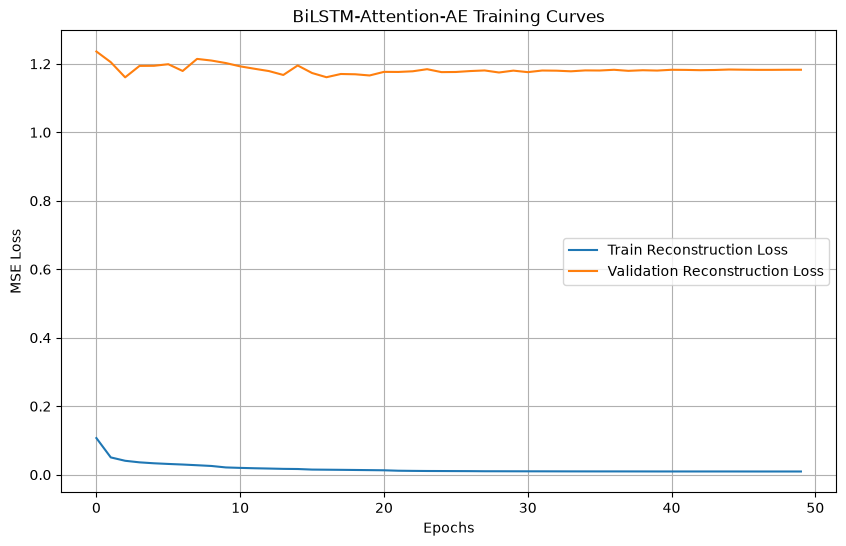

In [20]:
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='Train Reconstruction Loss')
plt.plot(val_losses, label='Validation Reconstruction Loss')
plt.title('BiLSTM-Attention-AE Training Curves')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True)
plt.savefig("results/figures/training_curves.png")
plt.show()

### 19. Reconstruction Error Analysis

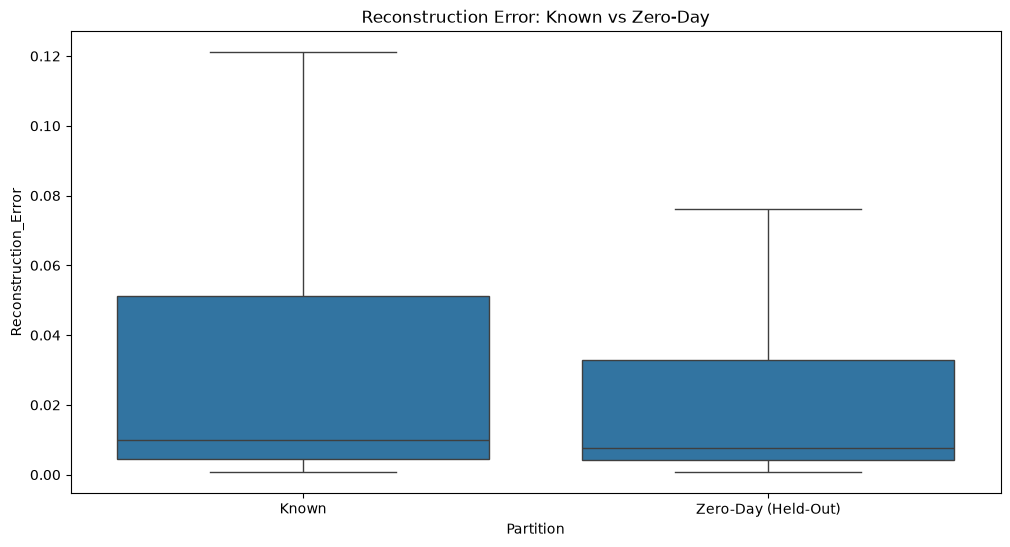

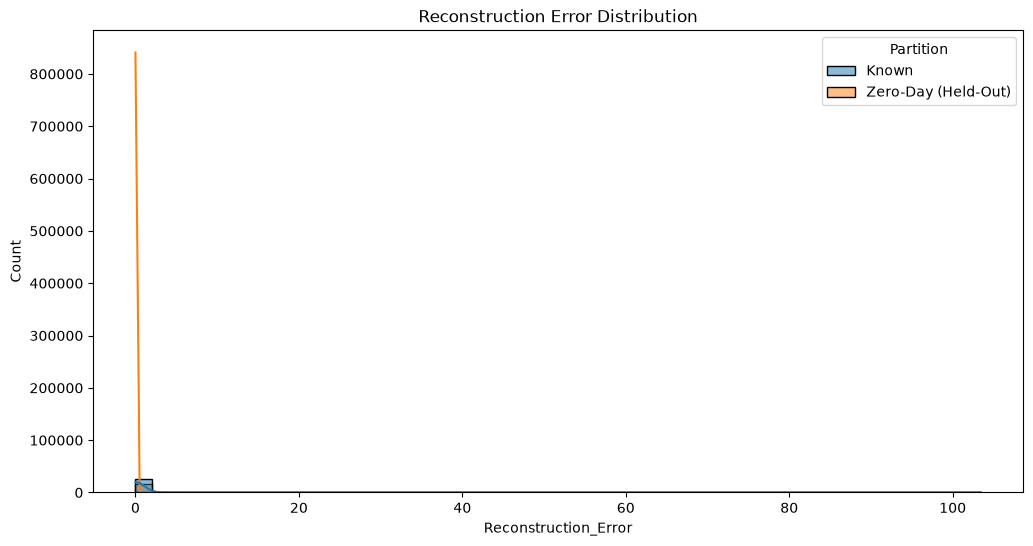

=== Reconstruction Error Metrics ===
                       count      mean       std       min       50%  \
Partition                                                              
Known                26578.0  1.160520  8.066454  0.000759  0.009996   
Zero-Day (Held-Out)  16101.0  0.032215  0.059077  0.000759  0.007672   

                          95%        99%         max  
Partition                                             
Known                0.233592  47.825597  103.448914  
Zero-Day (Held-Out)  0.148404   0.240323    1.372502  


In [21]:
def extract_metrics(loader, model_instance):
    model_instance.eval()
    errors = []
    latents = []
    attentions = []
    labels = []
    
    with torch.no_grad():
        for batch_x, batch_y in loader:
            batch_x = batch_x.to(device)
            x_hat, z, attn = model_instance(batch_x)
            
            err = compute_reconstruction_error(batch_x, x_hat).cpu().numpy()
            errors.extend(err)
            latents.append(z.cpu().numpy())
            attentions.append(attn.cpu().numpy())
            labels.extend(batch_y)
            
    return np.array(errors), np.concatenate(latents, axis=0), np.concatenate(attentions, axis=0), np.array(labels)

model.load_state_dict(torch.load("results/checkpoints/best_model.pt"))

val_errs, val_z, val_attn, val_y = extract_metrics(val_loader, model)
test_errs, test_z, test_attn, test_y = extract_metrics(test_loader, model)

# Create DataFrame for analysis
df_analysis = pd.DataFrame({
    'Reconstruction_Error': np.concatenate([val_errs, test_errs]),
    'Family': np.concatenate([val_y, test_y]),
    'Partition': ['Known'] * len(val_errs) + ['Zero-Day (Held-Out)'] * len(test_errs)
})

plt.figure(figsize=(12, 6))
sns.boxplot(x='Partition', y='Reconstruction_Error', data=df_analysis, showfliers=False)
plt.title('Reconstruction Error: Known vs Zero-Day')
plt.savefig("results/figures/reconstruction_boxplot.png")
plt.show()

plt.figure(figsize=(12, 6))
sns.histplot(data=df_analysis, x='Reconstruction_Error', hue='Partition', kde=True, bins=50)
plt.title('Reconstruction Error Distribution')
plt.savefig("results/figures/reconstruction_hist.png")
plt.show()

print("=== Reconstruction Error Metrics ===")
print(df_analysis.groupby('Partition')['Reconstruction_Error'].describe(percentiles=[.5, .95, .99]))

### 20. Latent Space Visualization

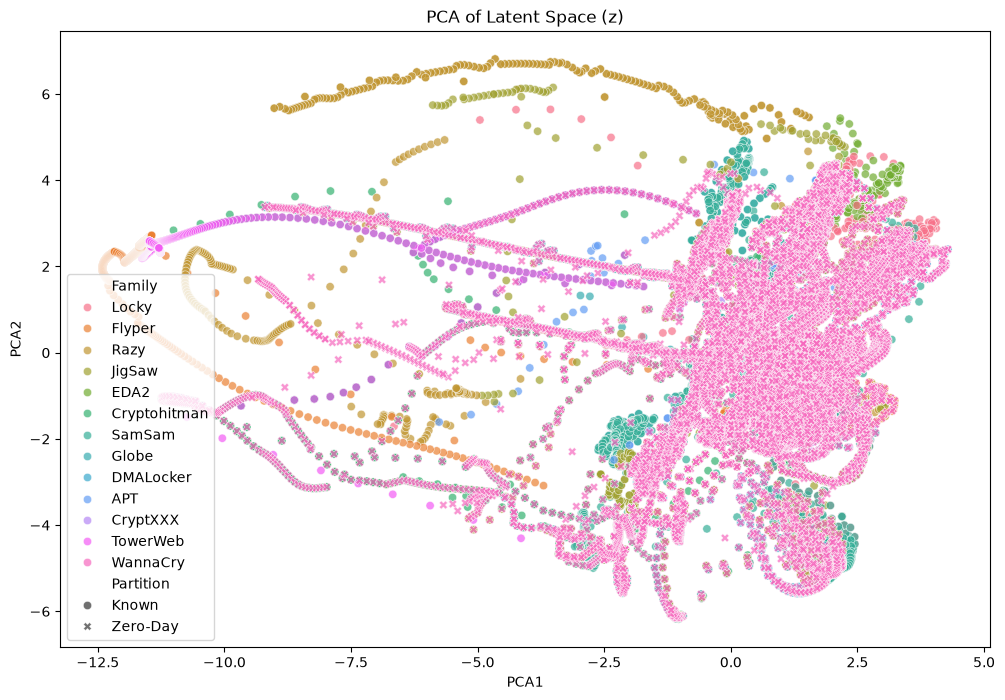

In [22]:
pca = PCA(n_components=2)
z_all = np.concatenate([val_z, test_z], axis=0)
z_pca = pca.fit_transform(z_all)

df_pca = pd.DataFrame({
    'PCA1': z_pca[:, 0],
    'PCA2': z_pca[:, 1],
    'Family': np.concatenate([val_y, test_y]),
    'Partition': ['Known'] * len(val_y) + ['Zero-Day'] * len(test_y)
})

plt.figure(figsize=(12, 8))
sns.scatterplot(x='PCA1', y='PCA2', hue='Family', style='Partition', data=df_pca, alpha=0.7)
plt.title('PCA of Latent Space (z)')
plt.savefig("results/figures/latent_pca.png")
plt.show()

### 21. Attention Visualization

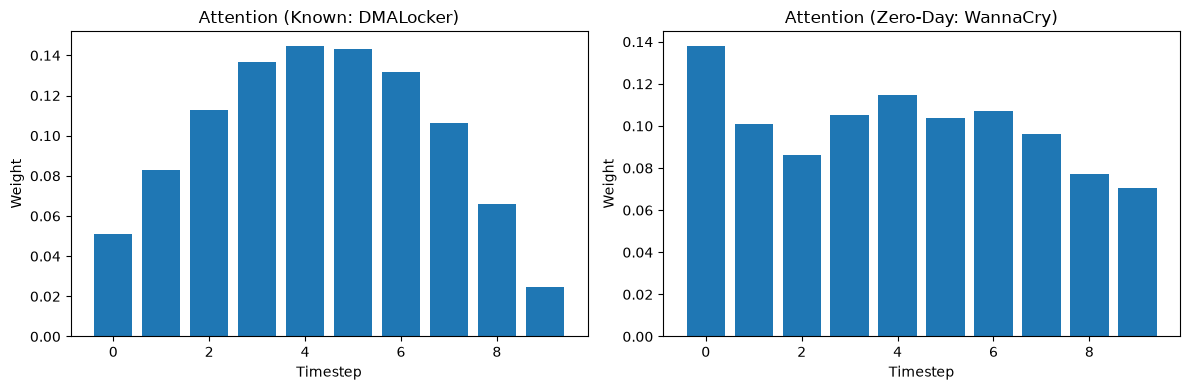

In [23]:
def plot_attention(idx_known, idx_unknown):
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.bar(range(window_size), val_attn[idx_known])
    plt.title(f'Attention (Known: {val_y[idx_known]})')
    plt.xlabel('Timestep')
    plt.ylabel('Weight')
    
    plt.subplot(1, 2, 2)
    plt.bar(range(window_size), test_attn[idx_unknown])
    plt.title(f'Attention (Zero-Day: {test_y[idx_unknown]})')
    plt.xlabel('Timestep')
    plt.ylabel('Weight')
    
    plt.tight_layout()
    plt.savefig("results/figures/attention_weights.png")
    plt.show()

if len(val_attn) > 0 and len(test_attn) > 0:
    plot_attention(random.randint(0, len(val_attn)-1), random.randint(0, len(test_attn)-1))

### 22. Plain LSTM-AE Baseline

In [24]:
class LSTMEncoderBaseline(nn.Module):
    def __init__(self, input_dim, hidden_size, num_layers, latent_dim, dropout):
        super(LSTMEncoderBaseline, self).__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=False, # Uni-directional
            dropout=dropout if num_layers > 1 else 0
        )
        self.latent_proj = nn.Linear(hidden_size, latent_dim)

    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        h_n_last_layer = h_n[-1] # (batch_size, hidden_size)
        z = self.latent_proj(h_n_last_layer)
        return z

class LSTMAutoencoderBaseline(nn.Module):
    def __init__(self, input_dim, seq_len, config):
        super(LSTMAutoencoderBaseline, self).__init__()
        self.encoder = LSTMEncoderBaseline(
            input_dim=input_dim,
            hidden_size=config['hidden_size'],
            num_layers=config['num_layers'],
            latent_dim=config['latent_dim'],
            dropout=config['dropout']
        )
        self.decoder = Decoder(
            latent_dim=config['latent_dim'],
            hidden_size=config['hidden_size'],
            num_layers=config['num_layers'],
            output_dim=input_dim,
            seq_len=seq_len,
            dropout=config['dropout']
        )

    def encode(self, x):
        return self.encoder(x), None # No attention

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        z, _ = self.encode(x)
        reconstruction = self.decode(z)
        return reconstruction, z, None

baseline_model = LSTMAutoencoderBaseline(input_dim=FEATURE_DIM, seq_len=window_size, config=CONFIG).to(device)
print(baseline_model)
print(f"Baseline Params: {sum(p.numel() for p in baseline_model.parameters() if p.requires_grad)}")

LSTMAutoencoderBaseline(
  (encoder): LSTMEncoderBaseline(
    (lstm): LSTM(18, 64, num_layers=2, batch_first=True, dropout=0.2)
    (latent_proj): Linear(in_features=64, out_features=64, bias=True)
  )
  (decoder): Decoder(
    (hidden_proj): Linear(in_features=64, out_features=64, bias=True)
    (lstm): LSTM(64, 64, num_layers=2, batch_first=True, dropout=0.2)
    (output_proj): Linear(in_features=64, out_features=18, bias=True)
  )
)
Baseline Params: 130834


### 23. Final Research Report

In [28]:
print("=== FED-EVT-OSAD: RESEARCH SUMMARY ===")
print(f"Dataset Size: {len(df)}")
print(f"Final Features: {FEATURE_DIM}")
print(f"Window Size: {window_size}")
print(f"Training Windows: {len(X_train_seq)}")
print(f"Latent Dimension: {CONFIG['latent_dim']}")
print(f"Model Parameters: {total_params}")
print(f"Best Val Loss: {best_val_loss:.6f}")
print("\nReconstruction Error (Median):")
print(f"Known Attacks (Val): {np.median(val_errs):.6f}")
print(f"Zero-Day ({held_out_family}): {np.median(test_errs):.6f}")

if np.median(test_errs) > np.median(val_errs):
    print("\nInterpretation: The held-out attack family exhibits elevated reconstruction error, indicating that the BiLSTM-Attention-AE effectively learned a bounded representation of known traffic and treats the zero-day family as anomalous.")
else:
    print("\nInterpretation: The zero-day family does not show significantly higher reconstruction error in this projection. Further tuning of features or prototype distance may be required.")

=== FED-EVT-OSAD: RESEARCH SUMMARY ===
Dataset Size: 149043
Final Features: 18
Window Size: 10
Training Windows: 106337
Latent Dimension: 64
Model Parameters: 230803
Best Val Loss: 1.160520

Reconstruction Error (Median):
Known Attacks (Val): 0.009996
Zero-Day (WannaCry): 0.007672

Interpretation: The zero-day family does not show significantly higher reconstruction error in this projection. Further tuning of features or prototype distance may be required.


### NEXT PHASE — FED-EVT-OSAD

The current model produces:
`z = encoder(x)`
`R(x) = reconstruction error`

Future modules will add:
1. **Prototype distance**: `D(x) = min_k distance(z, prototype_k)`
2. **Fused novelty**: `S(x) = λ * R_normalized(x) + (1 - λ) * D_normalized(x)`
3. **EVT Calibration**: 95th percentile threshold `u` -> GPD fitting -> EVT threshold `τ_i`
4. **Federated Aggregation**: Federated tail sharing + Evidence-weighted shrinkage.

*This notebook provides the stable encoder/decoder interface for these future extensions.*